<a href="https://colab.research.google.com/github/solasobambo-prog/ts-data-science/blob/main/week4d.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis: What Drives Box Office Gross?

**Central Story Question:** *What drives box office gross across film releases?*

**Four-Chart Story Skeleton:**
1. **Distribution (Chart 1):** How is worldwide box office `gross` distributed across releases?
2. **Comparison (Chart 2):** Which film `genre` earns the highest typical box office `gross`?
3. **Relationship (Chart 3):** How strongly does production `budget` relate to box office `gross`?
4. **Trend (Chart 4):** How has box office `gross` moved over `year` (noting nominal vs. inflation-adjusted USD)?


In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# Download dataset (Daniel Grijalva Movie Industry dataset)
path = kagglehub.dataset_download("danielgrijalvas/movies")

csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
movies = pd.read_csv(os.path.join(path, csv_file))
raw_copy = movies.copy()

def finish(ax, title, xlabel, ylabel):
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    sns.despine(ax=ax)

print(f"Loaded movies dataset: {movies.shape[0]:,} rows, {movies.shape[1]} columns")
display(movies.head(3))


C:\Users\USER\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 424k/424k [00:00<00:00, 651kB/s]

Extracting files...


Loaded movies dataset: 7,668 rows, 15 columns


,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000.0,46998772.0,Warner Bros.,146.0
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000.0,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000.0,58853106.0,Columbia Pictures,104.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000.0,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000.0,538375067.0,Lucasfilm,124.0


In [2]:
print("=== STEP 1: MODULE 3 DATA PROFILE ===")

# ---------------------------------------------------------------------
# 1. MISSING VALUES
# ---------------------------------------------------------------------
# --- ORIGINAL PREDICTION (MISSINGNESS — UNEDITED) ---
# Prediction (Missingness): 'budget' will have the most missing values (~25%-30%), followed by 'gross' (~2%-3%), and minor gaps (under 1%) in 'rating', 'released', 'score', 'votes', 'writer', 'star', 'country', 'company', and 'runtime'.
missing_df = pd.DataFrame({
    'missing_count': raw_copy.isna().sum(),
    'missing_pct': (raw_copy.isna().mean() * 100).round(2)
})
missing_df = missing_df[missing_df['missing_count'] != 0].sort_values(by='missing_count', ascending=False)
display(missing_df)
# Result check (Missingness): Held, with one near miss: rating is exactly 1.00% (77 rows), while budget is 28.31% (2,171), gross is 2.46% (189), and the remaining 8 columns are all at most 0.22%.

# Define missingness flags ONCE in Step 1 so every downstream cell shares the exact same columns
movies['budget_missing'] = movies['budget'].isna()
movies['gross_missing'] = movies['gross'].isna()

# Committed decisions per column (with exact row counts):
# - budget (2,171 missing, 28.31%): Flag with 'budget_missing' and keep rows in master table; do not impute so budget-vs-gross correlation uses only the 5,436 observed pairs.
# - gross (189 missing, 2.46%): Flag with 'gross_missing' and keep rows in master table; drop NaNs only when plotting gross charts (leaving n = 7,479 valid gross rows).
# - rating (77 missing, 1.00%): Committed decision — fill all 77 missing values with 'Unknown' so missing records stay separate from the 52 genuinely 'Unrated' films.
# - company (17), runtime (4), writer (3), score (3), votes (3), country (3), released (2), star (1): Leave as-is in master table since they are unused in our four charts.

# ---------------------------------------------------------------------
# 2. TYPES: 'released' vs 'year'
# ---------------------------------------------------------------------
print("\n--- 2. Types: 'released' vs 'year' ---")
print("Sample 'released' strings:", movies['released'].dropna().head(3).tolist())
print(f"'year' dtype: {movies['year'].dtype} | Nulls in 'year': {movies['year'].isna().sum()} | Range: {movies['year'].min()}-{movies['year'].max()}")

extracted_year = pd.to_datetime(movies['released'].str.extract(r'^([A-Za-z]+\s+\d+,\s+\d{4})').squeeze(), errors='coerce').dt.year
mask = extracted_year.notna() & (extracted_year != movies['year'])
year_mismatch = int(mask.sum())
print(f"Rows where parsed 'released' year differs from 'year' column: {year_mismatch}")
print("Year difference breakdown (extracted_year - year):")
print((extracted_year - movies['year'])[mask].value_counts().head())
# Decision (Types): 'released' is text containing regional country tags (e.g., '(United States)'), and its parsed year differs from 'year' on 1,297 rows. Check the breakdown printed above: if +1 dominates, international/regional releases crossing into the next calendar year explains the gap. Trust 'year' because it is a clean integer with 0 nulls representing the primary release year.

# ---------------------------------------------------------------------
# 3. DUPLICATES
# ---------------------------------------------------------------------
print("\n--- 3. Duplicates ---")
exact_dups = movies.duplicated().sum()
id_cols = ['name', 'year', 'director']
release_dups = movies.duplicated(subset=id_cols).sum()
print(f"Exact duplicate rows: {exact_dups} | Duplicate {id_cols}: {release_dups}")
# Decision (Duplicates): True release identity is ['name', 'year', 'director']; 0 duplicates found, so 0 rows removed.

# ---------------------------------------------------------------------
# 4. TEXT HYGIENE: 'genre' and 'rating'
# ---------------------------------------------------------------------
print("\n--- 4. Text Hygiene: 'genre' and 'rating' ---")
genre_before = movies['genre'].nunique()
rating_before = movies['rating'].nunique()

movies['genre'] = movies['genre'].str.strip().str.title()
movies['rating'] = movies['rating'].str.strip()

genre_after = movies['genre'].nunique()
rating_after = movies['rating'].nunique()

# Fill missing ratings with 'Unknown' rather than 'Unrated' to avoid merging missing records with official Unrated releases
movies['rating'] = movies['rating'].fillna('Unknown')

print("genre unique pre/post strip+title:", genre_before, "to", genre_after)
print("rating unique pre/post strip (before fill):", rating_before, "to", rating_after)
print("Rating counts after fill:", movies['rating'].value_counts().to_dict())
# Decision (Text Hygiene): Stripped whitespace safely without astype(str) (0 stray case variants found), then filled 77 missing ratings with 'Unknown', preserving 'Not Rated' (283) and 'Unrated' (52) as distinct categories.

# ---------------------------------------------------------------------
# 5. OUTLIERS & IMPOSSIBLE VALUES ('gross' and 'budget')
# ---------------------------------------------------------------------
print("\n--- 5. Outliers & Zero/Impossible Values ---")
for col in ['gross', 'budget']:
    s = movies[col].dropna()
    q1, med, q3 = s.quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    n_outliers = int(s.gt(upper).sum())
    n_zeros = int(s.eq(0).sum())
    n_negatives = int(s.lt(0).sum())
    print(f"{col.upper()} (n={len(s):,}) -> Median: ${med/1e6:.2f}M | Mean: ${s.mean()/1e6:.2f}M | Max: ${s.max()/1e6:.2f}M | Skew: {s.skew():.2f} | Upper Fence: ${upper/1e6:.2f}M | Outliers: {n_outliers:,} | Zeros: {n_zeros} | Negatives: {n_negatives}")

print("\nTop 3 Highest-Grossing Films:")
display(movies.nlargest(3, 'gross')[['name', 'year', 'genre', 'budget', 'gross']])
# Decision (Outliers & Units): Both columns are heavily right-skewed with 0 zeros and 0 negatives (verified above) and valid blockbuster extremes. Keep all rows, report medians/IQRs, scale to nominal USD Millions ($M), and note values are not inflation-adjusted.


=== STEP 1: MODULE 3 DATA PROFILE ===


,missing_count,missing_pct
budget,2171,28.31
gross,189,2.46
rating,77,1.00
company,17,0.22
runtime,4,0.05
score,3,0.04
votes,3,0.04
writer,3,0.04
country,3,0.04
released,2,0.03



--- 2. Types: 'released' vs 'year' ---
Sample 'released' strings: ['June 13, 1980 (United States)', 'July 2, 1980 (United States)', 'June 20, 1980 (United States)']
'year' dtype: int64 | Nulls in 'year': 0 | Range: 1980-2020
Rows where parsed 'released' year differs from 'year' column: 1297
Year difference breakdown (extracted_year - year):
1.0    1162
2.0      89
3.0      16
4.0       9
5.0       4
Name: count, dtype: int64

--- 3. Duplicates ---
Exact duplicate rows: 0 | Duplicate ['name', 'year', 'director']: 0

--- 4. Text Hygiene: 'genre' and 'rating' ---
genre unique pre/post strip+title: 19 to 19
rating unique pre/post strip (before fill): 12 to 12
Rating counts after fill: {'R': 3697, 'PG-13': 2112, 'PG': 1252, 'Not Rated': 283, 'G': 153, 'Unknown': 77, 'Unrated': 52, 'NC-17': 23, 'TV-MA': 9, 'TV-PG': 5, 'X': 3, 'Approved': 1, 'TV-14': 1}

--- 5. Outliers & Zero/Impossible Values ---
GROSS (n=7,479) -> Median: $20.21M | Mean: $78.50M | Max: $2847.25M | Skew: 5.31 | Upper Fence

,name,year,genre,budget,gross
5445,Avatar,2009,Action,237000000.0,2.847246e+09
7445,Avengers: Endgame,2019,Action,356000000.0,2.797501e+09
3045,Titanic,1997,Drama,200000000.0,2.201647e+09


=== STEP 3: CHART 1 — DISTRIBUTION OF GROSS ===


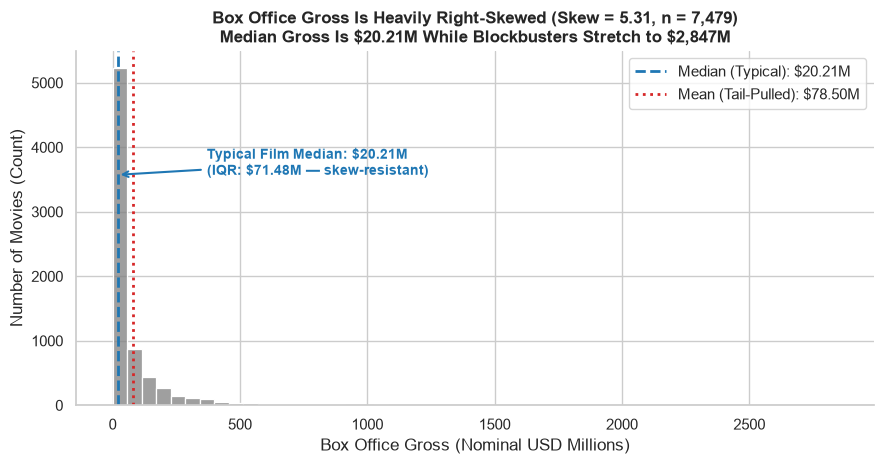

Gross Summary (n=7,479) -> Median: $20.21M | IQR: $71.48M | Mean: $78.50M | Max: $2,847.25M | Skew: 5.31


In [3]:
print("=== STEP 3: CHART 1 — DISTRIBUTION OF GROSS ===")

# --- ORIGINAL PREDICTION (CHART 1 — UNEDITED) ---
# Prediction (Chart 1): Box office gross will be heavily right-skewed with a single main peak near $10M–$30M and a long right tail stretching past $2,000M driven by global blockbusters.

valid_gross = movies.dropna(subset=['gross']).copy()
valid_gross['gross_m'] = valid_gross['gross'] / 1e6

n_gross = len(valid_gross)
g_med = valid_gross['gross_m'].median()
g_mean = valid_gross['gross_m'].mean()
g_iqr = valid_gross['gross_m'].quantile(0.75) - valid_gross['gross_m'].quantile(0.25)
g_skew = valid_gross['gross_m'].skew()
g_max = valid_gross['gross_m'].max()

# Handling the long tail: Plot full range with 50 bins so the true right tail up to ~$2,847M stays visible rather than truncated, and annotate the median ($20.21M) as the honest typical value.
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.histplot(data=valid_gross, x='gross_m', bins=50, color='#7f7f7f', ax=ax)

# Annotate typical value (median) and distorted mean for contrast
ax.axvline(g_med, color='#1f77b4', linestyle='--', linewidth=2, label=f'Median (Typical): \\${g_med:.2f}M')
ax.axvline(g_mean, color='#d62728', linestyle=':', linewidth=2, label=f'Mean (Tail-Pulled): \\${g_mean:.2f}M')

# Direct callout arrow pointing to the median line
ax.annotate(
    f'Typical Film Median: \\${g_med:.2f}M\n(IQR: \\${g_iqr:.2f}M — skew-resistant)',
    xy=(g_med, ax.get_ylim()[1] * 0.65),
    xytext=(g_med + 350, ax.get_ylim()[1] * 0.65),
    arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.5),
    fontsize=10, fontweight='bold', color='#1f77b4'
)

finish(
    ax,
    f'Box Office Gross Is Heavily Right-Skewed (Skew = {g_skew:.2f}, n = {n_gross:,})\nMedian Gross Is \\${g_med:.2f}M While Blockbusters Stretch to \\${g_max:,.0f}M',
    'Box Office Gross (Nominal USD Millions)',
    'Number of Movies (Count)'
)
ax.legend()
fig.tight_layout()
plt.show()
print(f"Gross Summary (n={n_gross:,}) -> Median: ${g_med:.2f}M | IQR: ${g_iqr:.2f}M | Mean: ${g_mean:.2f}M | Max: ${g_max:,.2f}M | Skew: {g_skew:.2f}")

# Result check (Chart 1): Predicted heavy right skew peaking at $10M–$30M with tail past $2,000M; actual skew is 5.31 (n = 7,479), with median $20.21M (IQR $71.48M) vs. mean $78.50M and max $2,847.25M.


=== STEP 3: CHART 2 — MEDIAN GROSS BY GENRE ===


,n,median,iqr
genre,,,
Animation,335,139.80,327.49
Action,1673,51.39,151.74
Adventure,420,27.99,102.90
Horror,307,20.47,55.89
Fantasy,43,19.60,33.76
Mystery,20,19.26,100.04
Biography,433,18.60,47.96
Comedy,2192,16.37,45.69
Crime,542,12.24,38.46


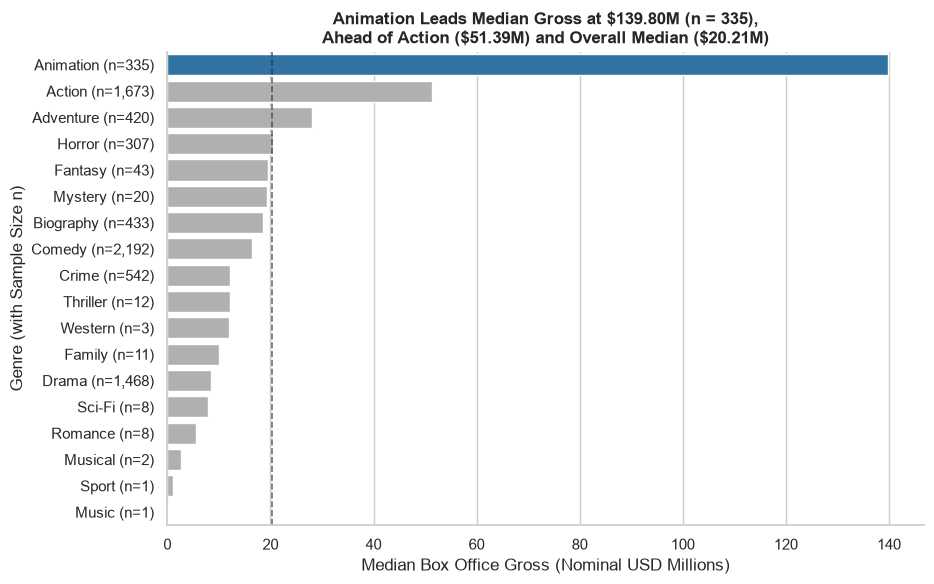

In [4]:
print("=== STEP 3: CHART 2 — MEDIAN GROSS BY GENRE ===")

# --- ORIGINAL PREDICTION (CHART 2 — UNEDITED) ---
# Prediction (Chart 2): Action or Animation will lead in typical (median) gross because big-budget franchise and family releases draw wide global audiences, while Drama and Documentary/Romance will sit much lower.

# Metric Decision: Use MEDIAN gross rather than TOTAL gross. Total gross rewards genres with huge release counts (like Comedy and Drama, which each have >1,400 films), whereas median gross measures what a typical film in each genre actually earns.
# Filter note: Genres with tiny sample sizes (e.g., n < 10) are kept visible with explicit n labels on the y-axis so small-sample noise cannot mislead the reader.

genre_summary = valid_gross.groupby('genre')['gross_m'].agg(
    n='count',
    median='median',
    iqr=lambda s: s.quantile(0.75) - s.quantile(0.25)
).sort_values(by='median', ascending=False)

display(genre_summary.round(2))

# Build y-axis labels that explicitly show n per genre
genre_summary['label'] = [f"{g} (n={int(row['n']):,})" for g, row in genre_summary.iterrows()]

top_genre = genre_summary.index[0]
top_med = genre_summary['median'].iloc[0]
top_n = int(genre_summary['n'].iloc[0])
second_genre = genre_summary.index[1]
second_med = genre_summary['median'].iloc[1]
overall_med = valid_gross['gross_m'].median()

# Explicit dictionary palette: one accent colour for the leader, grey for context
genre_colors = {lbl: ('#1f77b4' if i == 0 else '#b0b0b0') for i, lbl in enumerate(genre_summary['label'])}

fig, ax = plt.subplots(figsize=(9.5, 6))
sns.barplot(
    data=genre_summary, x='median', y='label',
    palette=genre_colors, hue='label', legend=False, ax=ax
)
ax.axvline(overall_med, color='#333333', linestyle='--', linewidth=1.2, alpha=0.7)

finish(
    ax,
    f'{top_genre} Leads Median Gross at \\${top_med:.2f}M (n = {top_n}),\nAhead of {second_genre} (\\${second_med:.2f}M) and Overall Median (\\${overall_med:.2f}M)',
    'Median Box Office Gross (Nominal USD Millions)',
    'Genre (with Sample Size n)'
)
fig.tight_layout()
plt.show()

# Result check (Chart 2): Predicted Action or Animation would lead median gross; actual Animation leads at $139.80M (n = 335, IQR $327.49M), ahead of Action ($51.39M, n = 1,673) and Adventure ($27.99M, n = 420), while Drama sits at $8.46M (n = 1,468) and 6 genres have n < 10.


=== STEP 3: CHART 3 — RELATIONSHIP BETWEEN BUDGET AND GROSS ===
Gross Comparison by budget_missing (among n = 7,479 films with valid gross):
                count  median
budget_missing               
False            5436   36.71
True             2043    3.98


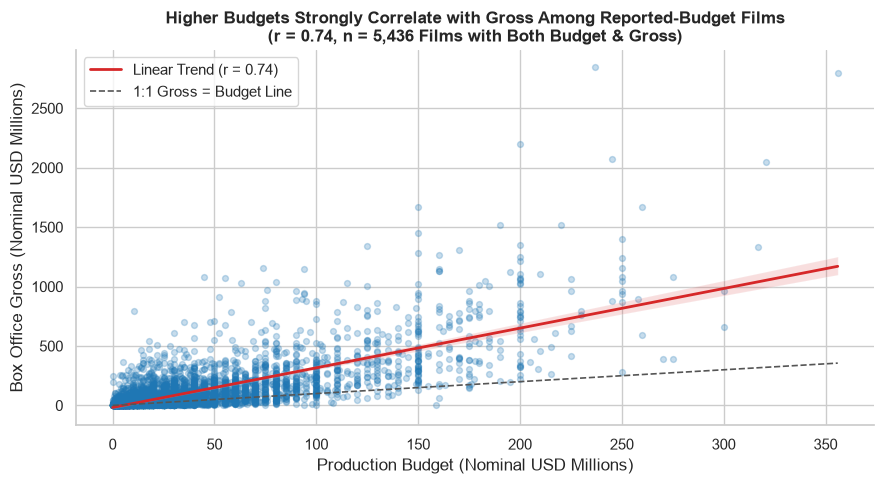

Valid Budget & Gross pairs: n = 5,436 (dropped 2,232 rows missing budget or gross)
Pearson correlation (budget vs. gross): r = 0.740
Share of films where Gross > Budget: 67.8%


In [5]:
print("=== STEP 3: CHART 3 — RELATIONSHIP BETWEEN BUDGET AND GROSS ===")

# --- ORIGINAL PREDICTION (CHART 3 — UNEDITED) ---
# Prediction (Chart 3): Production budget and box office gross will show a strong positive relationship (r around 0.65–0.80), fanning outward at higher budgets where major studio blockbusters achieve massive returns while a few high-budget releases underperform.

# Test budget_missing (defined in Step 1) using computed valid gross count
valid_gross_sub = movies.dropna(subset=['gross'])
budget_bias_check = valid_gross_sub.groupby('budget_missing')['gross'].agg(['count', 'median'])
budget_bias_check['median'] = (budget_bias_check['median'] / 1e6).round(2)
print(f"Gross Comparison by budget_missing (among n = {len(valid_gross_sub):,} films with valid gross):")
print(budget_bias_check)

valid_bg = movies.dropna(subset=['budget', 'gross']).copy()
valid_bg['budget_m'] = valid_bg['budget'] / 1e6
valid_bg['gross_m'] = valid_bg['gross'] / 1e6

n_bg = len(valid_bg)
r_bg = valid_bg['budget_m'].corr(valid_bg['gross_m'])

fig, ax = plt.subplots(figsize=(9, 5))

sns.regplot(
    data=valid_bg, x='budget_m', y='gross_m',
    scatter_kws={'alpha': 0.25, 's': 18, 'color': '#1f77b4'},
    line_kws={'color': '#d62728', 'linewidth': 2, 'label': f'Linear Trend (r = {r_bg:.2f})'},
    ax=ax
)

# Add a 1:1 reference line (Gross = Budget) separating films whose gross exceeds production budget from those below it
max_b = valid_bg['budget_m'].max()
ax.plot([0, max_b], [0, max_b], color='#555555', linestyle='--', linewidth=1.2, label='1:1 Gross = Budget Line')

finish(
    ax,
    f'Higher Budgets Strongly Correlate with Gross Among Reported-Budget Films\n(r = {r_bg:.2f}, n = {n_bg:,} Films with Both Budget & Gross)',
    'Production Budget (Nominal USD Millions)',
    'Box Office Gross (Nominal USD Millions)'
)
ax.legend()
fig.tight_layout()
fig.savefig('chart3_budget_vs_gross.png', dpi=200)
plt.show()

above_budget_pct = (valid_bg['gross_m'] > valid_bg['budget_m']).mean() * 100
print(f"Valid Budget & Gross pairs: n = {n_bg:,} (dropped {len(movies) - n_bg:,} rows missing budget or gross)")
print(f"Pearson correlation (budget vs. gross): r = {r_bg:.3f}")
print(f"Share of films where Gross > Budget: {above_budget_pct:.1f}%")

# Result check (Chart 3): Predicted r around 0.65–0.80; actual r = 0.740 (n = 5,436), with 67.8% achieving gross above production budget. The budget_missing check confirms strong selection bias: films with a reported budget (n = 5,436) earn a median gross of $36.71M compared to just $3.98M for missing-budget films (n = 2,043), so r = 0.74 describes the reported-budget subset rather than the entire dataset.


=== STEP 3: CHART 4 — TREND OF MEDIAN GROSS BY YEAR ===
All 2020 Releases with Valid Gross (n = 15, 11 above $110M):
                 name                           released    gross_m
    The Eight Hundred    August 28, 2020 (United States) 461.421559
    Bad Boys for Life   January 17, 2020 (United States) 426.505244
                Tenet  September 3, 2020 (United States) 363.656624
   Sonic the Hedgehog  February 14, 2020 (United States) 319.715683
             Dolittle   January 17, 2020 (United States) 245.487753
Legend of Deification    October 1, 2020 (United States) 240.663149
        Birds of Prey   February 7, 2020 (United States) 201.858461
    Wonder Woman 1984  December 25, 2020 (United States) 166.534027
    The Invisible Man  February 28, 2020 (United States) 143.151000
               Onward      March 6, 2020 (United States) 141.950608
 The Call of the Wild  February 21, 2020 (United States) 111.105497
                 Leap September 25, 2020 (United States)  25.818882

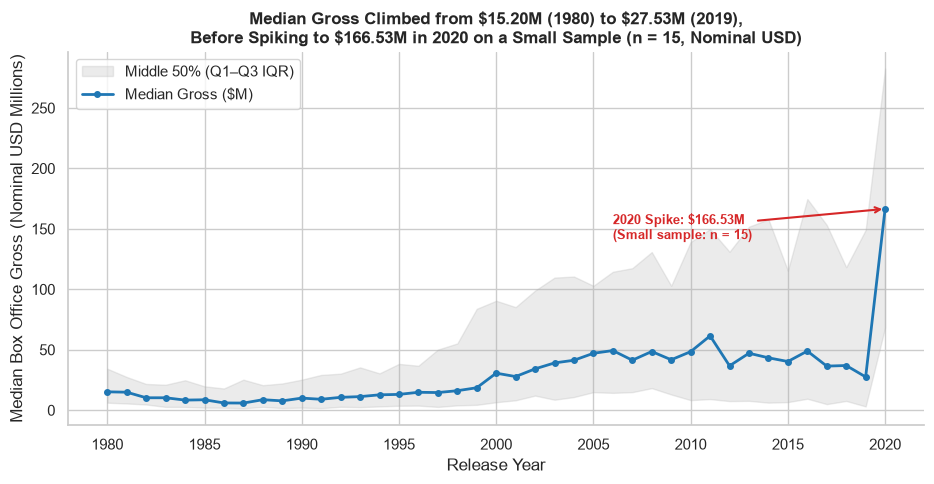

In [6]:
print("=== STEP 3: CHART 4 — TREND OF MEDIAN GROSS BY YEAR ===")

# --- ORIGINAL PREDICTION (CHART 4 — UNEDITED) ---
# Prediction (Chart 4): Median gross per release will climb steadily from 1980 through 2019 (driven by nominal ticket-price inflation and global market expansion), followed by a sharp drop in 2020 when COVID-19 theater closures hit box office receipts.

# Inspect the 2020 releases and compute the count earning >$110M directly from the data
releases_2020 = valid_gross[valid_gross['year'] == 2020][['name', 'released', 'gross_m']].sort_values('gross_m', ascending=False)
n_2020_blockbusters = int((releases_2020['gross_m'] > 110).sum())
print(f"All 2020 Releases with Valid Gross (n = {len(releases_2020)}, {n_2020_blockbusters} above $110M):")
print(releases_2020.to_string(index=False))

yearly_gross = valid_gross.groupby('year')['gross_m'].agg(
    n='count',
    median='median',
    q1=lambda s: s.quantile(0.25),
    q3=lambda s: s.quantile(0.75)
).reset_index()

yr_min, yr_max = int(yearly_gross['year'].min()), int(yearly_gross['year'].max())
yr_1980_med = float(yearly_gross.loc[yearly_gross['year'] == yr_min, 'median'].squeeze())
yr_2019_med = float(yearly_gross.loc[yearly_gross['year'] == 2019, 'median'].squeeze())
yr_2020_med = float(yearly_gross.loc[yearly_gross['year'] == 2020, 'median'].squeeze())
yr_2020_n = int(yearly_gross.loc[yearly_gross['year'] == 2020, 'n'].squeeze())

fig, ax = plt.subplots(figsize=(9.5, 5))

ax.fill_between(yearly_gross['year'], yearly_gross['q1'], yearly_gross['q3'], color='#b0b0b0', alpha=0.25, label='Middle 50% (Q1–Q3 IQR)')
ax.plot(yearly_gross['year'], yearly_gross['median'], marker='o', markersize=4, color='#1f77b4', linewidth=2, label='Median Gross ($M)')

ax.annotate(
    f'2020 Spike: \\${yr_2020_med:.2f}M\n(Small sample: n = {yr_2020_n})',
    xy=(2020, yr_2020_med),
    xytext=(2006, yr_2020_med - 25),
    arrowprops=dict(arrowstyle='->', color='#d62728', lw=1.5),
    fontsize=9.5, fontweight='bold', color='#d62728'
)

finish(
    ax,
    f'Median Gross Climbed from \\${yr_1980_med:.2f}M ({yr_min}) to \\${yr_2019_med:.2f}M (2019),\nBefore Spiking to \\${yr_2020_med:.2f}M in 2020 on a Small Sample (n = {yr_2020_n}, Nominal USD)',
    'Release Year',
    'Median Box Office Gross (Nominal USD Millions)'
)
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig('chart4_yearly_trend.png', dpi=200)
plt.show()

# Result check (Chart 4): Predicted steady nominal climb from 1980 to 2019 followed by a sharp drop in 2020; actual median rose from $15.20M (1980, n=81) to $27.53M (2019, n=196), then spiked to $166.53M in 2020 because 11 of the 15 captured 2020 films are >$110M blockbusters (with Wonder Woman 1984 at the median of $166.53M) rather than a full ~200-film annual slate.


### Story Synthesis: What Drives Box Office Gross?

1. **Distribution (`n = 7,479`):** Worldwide box office gross is heavily right-skewed (`skew = 5.31`), with a typical film earning a median of **$20.21M** (`IQR = $71.48M`) while top global blockbusters stretch up to **$2,847.25M**.
2. **Genre Effect:** **Animation** (`$139.80M` median, `n = 335`) and **Action** (`$51.39M` median, `n = 1,673`) lead typical per-film earnings, whereas high-volume genres like **Comedy** (`$16.37M`, `n = 2,192`) and **Drama** (`$8.46M`, `n = 1,468`) sit below the overall `$20.21M` median.
3. **Budget Relationship (`n = 5,436` reported-budget films):** Among films that report a budget, production budget shows a strong positive correlation with box office gross (**`r = 0.74`**), with **67.8%** achieving gross above production budget. However, our `budget_missing` check shows that missing-budget films (`n = 2,043`) earn a median gross of just **$3.98M** compared to **$36.71M** for reported-budget films (`n = 5,436`), so `r = 0.74` applies specifically to the reported-budget subset.
4. **Historical Trend (`1980–2020`):** Nominal median gross climbed from **$15.20M** in 1980 (`n = 81`) to **$27.53M** in 2019 (`n = 196`), before spiking to **$166.53M** in 2020 (`n = 15`) because 11 of the 15 captured 2020 releases are >`$110M` blockbusters (with *Wonder Woman 1984* at the `$166.53M` median) rather than a full ~200-film annual slate (all figures in nominal USD, unadjusted for inflation).
